# Hipótesis 1 · Análisis de incidentes por actividad en misiones de supervivencia

**Hipótesis:** Los incidentes registrados varían según la actividad que realizaba la persona, lo que permite identificar diferentes contextos para diseñar misiones de supervivencia marina.
**Pregunta:** ¿Qué actividades aparecen con mayor frecuencia en los registros y qué diferencias encontramos en sus ubicaciones, especies identificadas y consecuencias?

## 1. Carga de datos

In [3]:
%pip install xlrd


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("GSAF5_limpio.xls")

print("Dataset cargado correctamente")
print("Número de filas y columnas:", df.shape)

df.head()

Dataset cargado correctamente
Número de filas y columnas: (7125, 27)


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22,Fatal_review_reason,Country_needs_review,Country_original,State_original
0,18th September,2026.0,Unprovoked,Australia,Western australia,Sorrento beach perth,Swimming,Greg O'Neil,M,63.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Australia,Western Australia
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of perce le bilbo dive site,Diving,Unknown Male,M,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Canada,Quebec
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini island,Swimming,Unknown Austrian Tourist,F,37.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Bahamas,Bimini
3,13th September,2026.0,Unprovoked,Australia,Western australia,Geraldton,Surfing,Mel Ismail,M,50.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Australia,Western Australia
4,7th September,2026.0,Unprovoked,Usa,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,USA,Hawaii


## Frecuencia de las actividades más registradas

In [5]:
df_analisis = df[[
    "Country", "State", "Location", "Activity",
    "Injury", "Fatal Y/N", "Species "
]].copy()

df_analisis.columns = [
    "Country", "State", "Location", "Activity",
    "Injury", "Fatal", "Species"
]

for col in df_analisis.columns:
    df_analisis[col] = (
        df_analisis[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

df_analisis.head()

,Country,State,Location,Activity,Injury,Fatal,Species
0,Australia,Western australia,Sorrento beach perth,Swimming,Body not recovered,Y,Great white shark 6m
1,Canada,Quebec,Off the coast of perce le bilbo dive site,Diving,Injuries to chest shoulder and back,N,Great white shark
2,Bahamas,Bimini,Bimini island,Swimming,Serious injuries to right ankle,N,Unknown
3,Australia,Western australia,Geraldton,Surfing,Foot lost in attack,N,Unknown
4,Usa,Hawaii,Honolulu,Surfing,Scrapes on inside of legs,N,Tiger shark suspected


In [7]:
%pip install seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("GSAF5_limpio.xls")

print("Dimensiones del dataset:", df.shape)
print("\nColumnas disponibles:")
print(df.columns.tolist())

df.head()

Dimensiones del dataset: (7125, 27)

Columnas disponibles:
['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity', 'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ', 'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1', 'original order', 'Unnamed: 21', 'Unnamed: 22', 'Fatal_review_reason', 'Country_needs_review', 'Country_original', 'State_original']


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22,Fatal_review_reason,Country_needs_review,Country_original,State_original
0,18th September,2026.0,Unprovoked,Australia,Western australia,Sorrento beach perth,Swimming,Greg O'Neil,M,63.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Australia,Western Australia
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of perce le bilbo dive site,Diving,Unknown Male,M,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Canada,Quebec
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini island,Swimming,Unknown Austrian Tourist,F,37.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Bahamas,Bimini
3,13th September,2026.0,Unprovoked,Australia,Western australia,Geraldton,Surfing,Mel Ismail,M,50.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Australia,Western Australia
4,7th September,2026.0,Unprovoked,Usa,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,USA,Hawaii


,Número de registros,% del total
Activity,,
Surfing,1162,16.31
Swimming,1076,15.10
Unknown,590,8.28
Fishing,514,7.21
Spearfishing,406,5.70
Wading,178,2.50
Bathing,167,2.34
Diving,155,2.18
Snorkeling,139,1.95


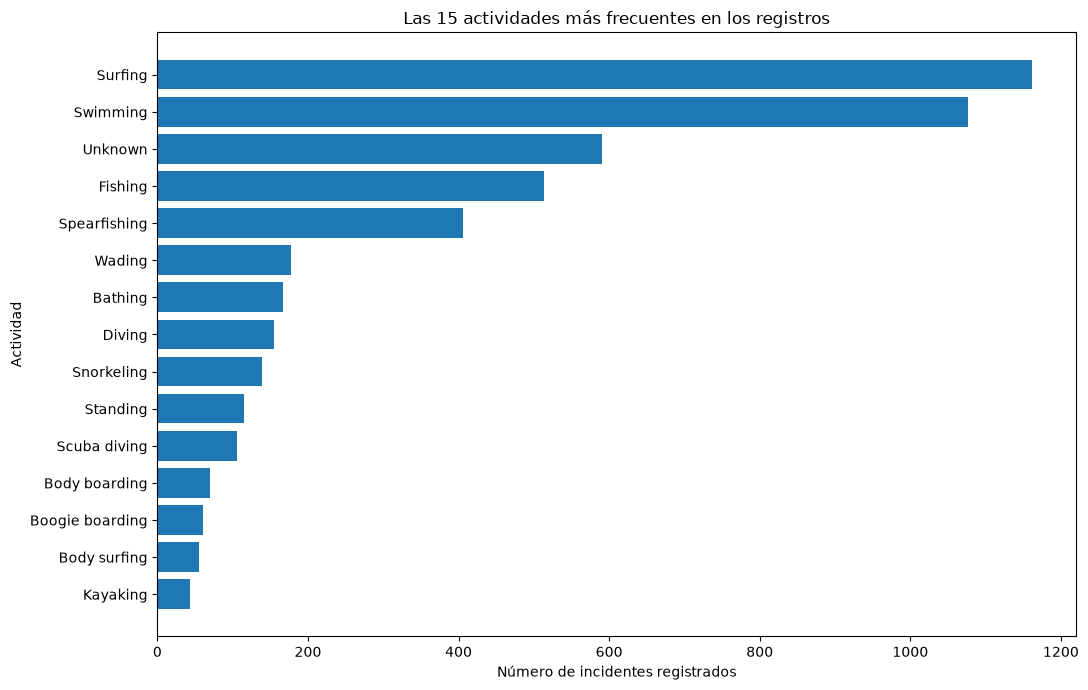

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Crear una tabla de trabajo con las columnas del proyecto
df_analisis = df[[
    "Country", "State", "Location", "Activity",
    "Injury", "Fatal Y/N", "Species "
]].copy()

df_analisis.columns = [
    "Country", "State", "Location", "Activity",
    "Injury", "Fatal", "Species"
]

# Limpiar espacios y tratar las etiquetas de valores desconocidos
for col in df_analisis.columns:
    df_analisis[col] = (
        df_analisis[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

# Calcular frecuencias de actividad
frecuencias = df_analisis["Activity"].value_counts()

tabla_actividad = pd.DataFrame({
    "Número de registros": frecuencias,
    "% del total": (frecuencias / len(df_analisis) * 100).round(2)
})

display(tabla_actividad.head(15))

# Gráfico de las 15 actividades más frecuentes
top_15 = frecuencias.head(15).sort_values()

plt.figure(figsize=(11, 7))
plt.barh(top_15.index, top_15.values)
plt.title("Las 15 actividades más frecuentes en los registros")
plt.xlabel("Número de incidentes registrados")
plt.ylabel("Actividad")
plt.tight_layout()
plt.show()

## Análisis de las ubicaciones por actividad

In [10]:
# Excluir etiquetas desconocidas al buscar ubicaciones frecuentes
desconocidos = {"unknown", "nan", "", "not recorded", "unrecorded"}

actividades_principales = (
    df_analisis.loc[
        ~df_analisis["Activity"].str.lower().isin(desconocidos),
        "Activity"
    ]
    .value_counts()
    .head(5)
    .index
)

for actividad in actividades_principales:
    subconjunto = df_analisis[
        df_analisis["Activity"] == actividad
    ]

    print(f"\n{'=' * 50}")
    print(f"ACTIVIDAD: {actividad}")
    print(f"Total de registros: {len(subconjunto)}")

    for columna in ["Country", "State", "Location"]:
        datos = subconjunto.loc[
            ~subconjunto[columna].str.lower().isin(desconocidos),
            columna
        ]

        print(f"\nTop 10 de {columna}:")
        display(datos.value_counts().head(10).to_frame("Registros"))


ACTIVIDAD: Surfing
Total de registros: 1162

Top 10 de Country:


,Registros
Country,
Usa,674
Australia,259
South africa,100
Brazil,39
Reunion,21
New zealand,17
Indonesia,7
Mexico,7
Costa rica,4



Top 10 de State:


,Registros
State,
Florida,422
New south wales,133
California,89
Hawaii,76
Eastern cape province,60
Western australia,45
Pernambuco,32
South australia,30
Oregon,25



Top 10 de Location:


...

,Registros
Country,
Usa,124
Australia,18
South africa,9
Mexico,6
Spain,3
New zealand,2
Brazil,2
Grenada,2
Papua new guinea,2



Top 10 de State:


,Registros
State,
Florida,78
North carolina,14
Texas,7
Western australia,6
South carolina,6
Queensland,4
California,4
New south wales,4
Louisiana,4



Top 10 de Location:


,Registros
Location,
"New smyrna beach, volusia county",13
"Daytona beach, volusia county",9
"Oak island, brunswick county",3
"Cocoa beach, brevard county",3
"Sanibel island, lee county",3
New smyrna beach,2
"Ponce inlet, volusia county",2
"Fort lauderdale, broward county",2
"Fernandina beach, nassau county",2


## Análisis de las especies de tiburón por actividad

In [11]:
for actividad in actividades_principales:
    subconjunto = df_analisis[
        df_analisis["Activity"] == actividad
    ]

    especies_conocidas = subconjunto.loc[
        ~subconjunto["Species"].str.lower().isin(desconocidos),
        "Species"
    ]

    print(f"\nActividad: {actividad}")
    print(f"Registros totales: {len(subconjunto)}")
    print(f"Registros con especie identificada: {len(especies_conocidas)}")
    print(
        "Porcentaje con especie desconocida:",
        round(
            (
                subconjunto["Species"]
                .str.lower()
                .isin(desconocidos)
                .mean()
                * 100
            ),
            2
        ),
        "%"
    )

    display(
        especies_conocidas
        .value_counts()
        .head(10)
        .to_frame("Registros")
    )


Actividad: Surfing
Registros totales: 1162
Registros con especie identificada: 453
Porcentaje con especie desconocida: 61.02 %


,Registros
Species,
White shark,39
Tiger shark,16
Bull shark,11
Blacktip or spinner shark,8
Wobbegong shark,7
Unidentified species,6
Bronze whaler,5
"White shark, 3.5 m",5
Blacktip shark,5



Actividad: Swimming
Registros totales: 1076
Registros con especie identificada: 321
Porcentaje con especie desconocida: 70.17 %


,Registros
Species,
Bull shark,26
White shark,24
Tiger shark,18
Wobbegong shark,10
Thought to involve a zambesi shark,5
Raggedtooth shark,5
"Bull shark, 4' to 5'",4
Sand shark,4
Zambesi shark,4



Actividad: Fishing
Registros totales: 514
Registros con especie identificada: 225
Porcentaje con especie desconocida: 56.23 %


,Registros
Species,
White shark,19
Tiger shark,6
Bull shark,4
Grey nurse shark,4
Blue shark,3
Mako shark,3
A small shark',3
Raggedtooth shark,2
Reef shark,2



Actividad: Spearfishing
Registros totales: 406
Registros con especie identificada: 241
Porcentaje con especie desconocida: 40.64 %


,Registros
Species,
Bull shark,14
White shark,11
Tiger shark,10
Reef shark,5
"Bull shark, 6'",3
Blacktip shark,3
Zambesi shark,3
Bronze whaler shark,3
Wobbegong shark,3



Actividad: Wading
Registros totales: 178
Registros con especie identificada: 40
Porcentaje con especie desconocida: 77.53 %


,Registros
Species,
Bull shark,3
Blacktip shark,2
Angel shark,2
Not specified bull shark highly suspect,1
Sevengill shark,1
Blue shark,1
"Blacktip shark, 6'",1
"Bull shark, 4' to 6'",1
Reported as shark attacks but injuries caused by toadfish,1


## Análisis de las consecuencias: incidentes fatales y no fatales

Fatal_clean,N,UNKNOWN,Y
Activity,,,
Fishing,436,26,52
Spearfishing,319,30,57
Surfing,1049,48,65
Swimming,621,106,349
Wading,152,11,15


Fatal_clean,N,Y
Activity,,
Fishing,89.34,10.66
Spearfishing,84.84,15.16
Surfing,94.17,5.83
Swimming,64.02,35.98
Wading,91.02,8.98


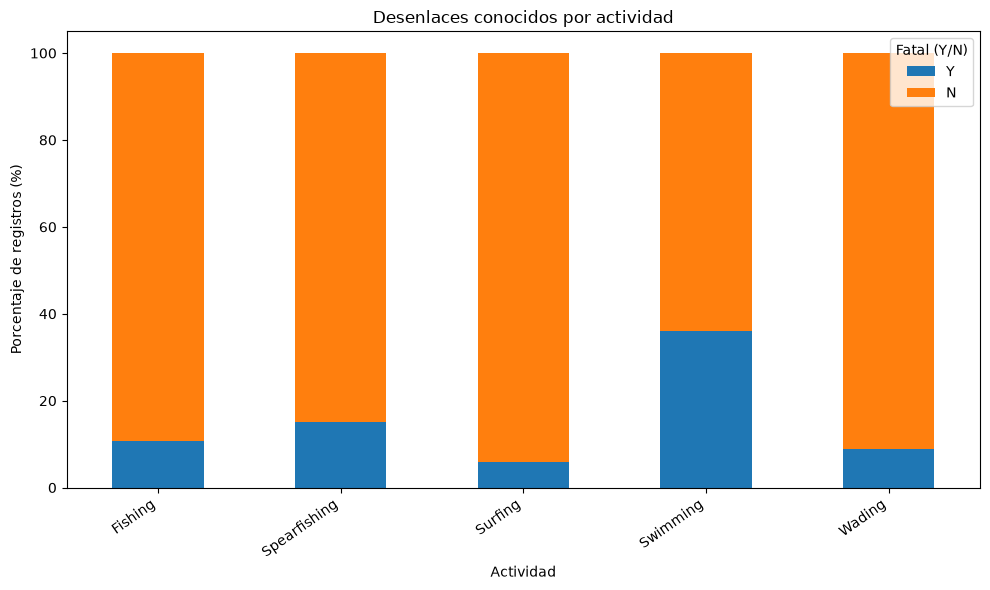

In [12]:
df_analisis["Fatal_clean"] = (
    df_analisis["Fatal"]
    .str.strip()
    .str.upper()
)

# Solo desenlaces conocidos Y/N
df_fatal_conocido = df_analisis[
    df_analisis["Fatal_clean"].isin(["Y", "N"])
].copy()

# Recuento por actividad y desenlace
tabla_fatal = pd.crosstab(
    df_analisis["Activity"],
    df_analisis["Fatal_clean"]
)

display(tabla_fatal.loc[
    tabla_fatal.index.isin(actividades_principales)
])

# Porcentajes dentro de cada actividad, solo para Y/N conocidos
tabla_fatal_pct = pd.crosstab(
    df_fatal_conocido["Activity"],
    df_fatal_conocido["Fatal_clean"],
    normalize="index"
) * 100

display(
    tabla_fatal_pct.loc[
        tabla_fatal_pct.index.isin(actividades_principales)
    ].round(2)
)

# Gráfico
grafico_fatal = tabla_fatal_pct.loc[
    tabla_fatal_pct.index.isin(actividades_principales),
    ["Y", "N"]
]

grafico_fatal.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Desenlaces conocidos por actividad")
plt.xlabel("Actividad")
plt.ylabel("Porcentaje de registros (%)")
plt.legend(title="Fatal (Y/N)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Análisis de las lesiones y consecuencias descritas

In [13]:
for actividad in actividades_principales:
    subconjunto = df_analisis[
        df_analisis["Activity"] == actividad
    ]

    injury_conocida = subconjunto.loc[
        ~subconjunto["Injury"].str.lower().isin(desconocidos),
        "Injury"
    ]

    print(f"\nActividad: {actividad}")
    print(f"Total de registros: {len(subconjunto)}")
    print(f"Descripciones de Injury disponibles: {len(injury_conocida)}")

    display(
        injury_conocida
        .value_counts()
        .head(10)
        .to_frame("Número de registros")
    )


Actividad: Surfing
Total de registros: 1162
Descripciones de Injury disponibles: 1153


,Número de registros
Injury,
Fatal,48
Foot bitten,37
Left foot bitten,29
"No injury, board bitten",27
No injury,20
"No injury, surfboard bitten",17
Right foot bitten,16
Leg bitten,15
Survived,15



Actividad: Swimming
Total de registros: 1076
Descripciones de Injury disponibles: 1066


,Número de registros
Injury,
Fatal,226
Foot bitten,16
Leg bitten,15
Right foot bitten,10
"Fatal, body not recovered",8
Lacerations to left foot,7
Minor injury,7
Lacerations to leg,6
Lacerations to foot,6



Actividad: Fishing
Total de registros: 514
Descripciones de Injury disponibles: 512


,Número de registros
Injury,
Fatal,28
No injury to occupants,8
Leg bitten,6
Finger bitten by hooked shark provoked incident,5
Forearm bitten by hooked shark provoked incident,4
"No injury to occupants, shark bit boat",4
Survived,4
No injury,4
Arm bitten,3



Actividad: Spearfishing
Total de registros: 406
Descripciones de Injury disponibles: 402


,Número de registros
Injury,
Fatal,24
No injury,9
Leg bitten,8
Minor injury,5
Calf bitten,5
Shoulder bitten,4
Right arm bitten,4
Right leg bitten,4
Thigh bitten,4



Actividad: Wading
Total de registros: 178
Descripciones de Injury disponibles: 175


,Número de registros
Injury,
Fatal,5
Foot bitten,4
Lacerations to lower leg,3
Lacerations to foot,3
Left foot bitten,3
Minor injury to left foot,2
Right foot bitten,2
Right leg bitten,2
Thigh bitten,2


## Tabla resumen de resultados de la hipótesis 1

In [14]:
filas_resumen = []

for actividad in actividades_principales:
    sub = df_analisis[
        df_analisis["Activity"] == actividad
    ].copy()

    total = len(sub)

    # País más frecuente, excluyendo desconocidos
    paises = sub.loc[
        ~sub["Country"].str.lower().isin(desconocidos),
        "Country"
    ]

    # Especie más frecuente, excluyendo desconocidos
    especies = sub.loc[
        ~sub["Species"].str.lower().isin(desconocidos),
        "Species"
    ]

    # Desenlaces conocidos
    fatal = sub["Fatal_clean"]
    conocidos = fatal.isin(["Y", "N"])
    total_conocidos = conocidos.sum()
    total_fatales = (fatal == "Y").sum()

    filas_resumen.append({
        "Actividad": actividad,
        "Registros": total,
        "% del dataset": round(total / len(df_analisis) * 100, 2),
        "País más frecuente": (
            paises.value_counts().index[0]
            if len(paises) else "Sin datos"
        ),
        "Especie identificada más frecuente": (
            especies.value_counts().index[0]
            if len(especies) else "Sin datos"
        ),
        "Fatal (Y)": int((fatal == "Y").sum()),
        "No fatal (N)": int((fatal == "N").sum()),
        "Desconocido/otro": int((~conocidos).sum()),
        "% fatal entre Y/N conocidos": (
            round(total_fatales / total_conocidos * 100, 2)
            if total_conocidos else np.nan
        )
    })

resumen_hipotesis = pd.DataFrame(filas_resumen)

display(resumen_hipotesis)

,Actividad,Registros,% del dataset,País más frecuente,Especie identificada más frecuente,Fatal (Y),No fatal (N),Desconocido/otro,% fatal entre Y/N conocidos
0,Surfing,1162,16.31,Usa,White shark,65,1049,48,5.83
1,Swimming,1076,15.10,Usa,Bull shark,349,621,106,35.98
2,Fishing,514,7.21,Usa,White shark,52,436,26,10.66
3,Spearfishing,406,5.70,Australia,Bull shark,57,319,30,15.16
4,Wading,178,2.50,Usa,Bull shark,15,152,11,8.98


## Conclusiones

El análisis de los 7.125 registros muestra que los incidentes documentados se distribuyen de forma desigual según la actividad realizada. Las categorías más frecuentes son Surfing, con 1.162 registros (16,31 % del total), y Swimming, con 1.076 (15,10 %). A continuación aparecen Fishing, con 514 registros, y Spearfishing, con 406.

En cuanto a la distribución geográfica, Estados Unidos es el país con más registros para Surfing, Swimming, Fishing y Wading, mientras que Australia ocupa el primer lugar en Spearfishing. Estos resultados permiten identificar contextos geográficos recurrentes, aunque no demuestran por sí solos que sean las zonas con mayor riesgo real.

La información sobre especies debe interpretarse con cautela, ya que el 64,45 % de los registros tiene la especie identificada como desconocida. Entre las especies identificadas aparecen con frecuencia White shark, Tiger shark y Bull shark, pero la información disponible no permite atribuirles un nivel de peligrosidad a partir de estos recuentos.

También se observan diferencias en los desenlaces documentados. Entre los registros con resultado conocido, el porcentaje marcado como fatal es del 5,83 % en Surfing, del 35,98 % en Swimming, del 10,66 % en Fishing, del 15,16 % en Spearfishing y del 8,98 % en Wading. Estas cifras describen los registros analizados y no deben interpretarse como probabilidades de sufrir un desenlace fatal al practicar cada actividad.

En conjunto, los resultados permiten considerar la hipótesis apoyada de forma descriptiva: la actividad registrada se relaciona con diferencias en las ubicaciones, las especies identificadas y los desenlaces documentados. Sin embargo, las limitaciones de los datos impiden afirmar que la actividad sea la causa de esas diferencias o que las frecuencias observadas representen el riesgo real.

Para el videojuego, los hallazgos pueden servir como base documental para diseñar misiones con distintas actividades, ubicaciones y situaciones de supervivencia. Las mecánicas concretas deberán presentarse como decisiones creativas inspiradas en los datos, no como conclusiones demostradas por ellos.